## TL

Este notebook lo he preparado para que se pueda lanzar en local y en kaggle

#### Preparación e instalación de dependencias

In [ ]:
# CHECK PARA VER SI ESTAMOS EN KAGGLE O LOCAL
import os
_DATASET_PATH = ''
_RUNTIME = ''

# Cambiar a True si no queremos que se ejecute la matrix de confusión y solo queremos hacer las pruebas con Test
_FAST_EXEC = True

if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    print("Running on Kaggle")
    _DATASET_PATH = '/kaggle/input/xview-recognition'
    _RUNTIME = 'KAGGLE'
else:
    print("Running Locally")
    _DATASET_PATH = '../xview_recognition'
    _RUNTIME = 'LOCAL'

Running Locally


In [2]:
import tensorflow as tf

if _RUNTIME == 'KAGGLE':
    !pip install rasterio

print(tf.config.list_physical_devices('GPU'))

2025-11-23 18:41:13.543784: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/m1tus/miniconda3/envs/pyCV/lib/python3.10/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


#### Preparación de datos

In [3]:
import uuid
import numpy as np

class GenericObject:
    """
    Generic object data.
    """
    def __init__(self):
        self.id = uuid.uuid4()
        self.bb = (-1, -1, -1, -1)
        self.category= -1
        self.score = -1

class GenericImage:
    """
    Generic image data.
    """
    def __init__(self, filename):
        self.filename = filename
        self.tile = np.array([-1, -1, -1, -1])
        self.objects = list([])

    def add_object(self, obj: GenericObject):
        self.objects.append(obj)

In [4]:
categories = {0: 'Cargo plane', 1: 'Small car', 2: 'Bus', 3: 'Truck', 4: 'Motorboat', 5: 'Fishing vessel', 6: 'Dump truck', 7: 'Excavator', 8: 'Building', 9: 'Helipad', 10: 'Storage tank', 11: 'Shipping container', 12: 'Pylon'}

In [ ]:
import warnings
import rasterio
import numpy as np

def load_geoimage(filename):
    warnings.filterwarnings('ignore', category=rasterio.errors.NotGeoreferencedWarning)
    src_raster = rasterio.open(_DATASET_PATH+'/'+filename, 'r')
    # RasterIO to OpenCV (see inconsistencies between libjpeg and libjpeg-turbo)
    input_type = src_raster.profile['dtype']
    input_channels = src_raster.count
    img = np.zeros((src_raster.height, src_raster.width, src_raster.count), dtype=input_type)
    for band in range(input_channels):
        img[:, :, band] = src_raster.read(band+1)
    return img

#### Training

In [ ]:
import json

# Load database
json_file = _DATASET_PATH+'/xview_ann_train.json'
with open(json_file) as ifs:
    json_data = json.load(ifs)
ifs.close()

In [7]:
import numpy as np

counts = dict.fromkeys(categories.values(), 0)
anns = []
for json_img, json_ann in zip(json_data['images'].values(), json_data['annotations'].values()):
    image = GenericImage(json_img['filename'])
    image.tile = np.array([0, 0, json_img['width'], json_img['height']])
    obj = GenericObject()
    obj.bb = (int(json_ann['bbox'][0]), int(json_ann['bbox'][1]), int(json_ann['bbox'][2]), int(json_ann['bbox'][3]))
    obj.category = json_ann['category_id']
    # Resampling strategy to reduce training time
    counts[obj.category] += 1
    image.add_object(obj)
    anns.append(image)
print(counts)

{'Cargo plane': 635, 'Small car': 3324, 'Bus': 1768, 'Truck': 2210, 'Motorboat': 1069, 'Fishing vessel': 706, 'Dump truck': 1236, 'Excavator': 789, 'Building': 3594, 'Helipad': 111, 'Storage tank': 1469, 'Shipping container': 1523, 'Pylon': 312}


In [8]:
from sklearn.model_selection import train_test_split

anns_train, anns_valid = train_test_split(anns, test_size=0.1, random_state=1, shuffle=True)
print('Number of training images: ' + str(len(anns_train)))
print('Number of validation images: ' + str(len(anns_valid)))

Number of training images: 16871
Number of validation images: 1875


In [9]:
# Load architecture (two-phase training setup)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout, GlobalAveragePooling2D, Flatten
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, Input

# Data augmentation stays as before
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

print('Load model')

# Phase 1: backbone as frozen feature extractor
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

model = Sequential()

model.add(Input(shape=(224, 224, 3)))
model.add(data_augmentation)
model.add(base_model)
model.add(GlobalAveragePooling2D())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(len(categories), activation='softmax'))
model.summary()

I0000 00:00:1763919676.237828   59592 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9709 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:07:00.0, compute capability: 8.6


Load model


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │         1,677 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,215,216 (16.08 MB)

 Trainable params: 165,645 (647.05 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
from tensorflow.keras.optimizers import AdamW

# Fase 1
opt_phase1 = AdamW(learning_rate=1e-3, beta_1=0.9, beta_2=0.999, epsilon=1e-8, amsgrad=True, clipnorm=1.0)

# Fase 2
opt_phase2 = AdamW(learning_rate=1e-5)

model.compile(optimizer=opt_phase1, loss='categorical_crossentropy', metrics=['accuracy'])

In [11]:
from tensorflow.keras.callbacks import TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Callbacks
model_checkpoint = ModelCheckpoint('model.keras', monitor='val_accuracy', verbose=1, save_best_only=True)
reduce_lr = ReduceLROnPlateau('val_accuracy', factor=0.5, patience=5, verbose=1)
early_stop = EarlyStopping('val_accuracy', patience=15, verbose=1, restore_best_weights=True)
terminate = TerminateOnNaN()
callbacks = [model_checkpoint, reduce_lr, early_stop, terminate]

In [12]:
def generator_images(objs, batch_size, do_shuffle=False):
    while True:
        if do_shuffle:
            np.random.shuffle(objs)
        groups = [objs[i:i+batch_size] for i in range(0, len(objs), batch_size)]
        for group in groups:
            images, labels = [], []
            for (filename, obj) in group:
                # Load image
                images.append(load_geoimage(filename))
                probabilities = np.zeros(len(categories))
                probabilities[list(categories.values()).index(obj.category)] = 1
                labels.append(probabilities)
            images = np.array(images).astype(np.float32)
            labels = np.array(labels).astype(np.float32)
            yield images, labels

In [13]:
# Generate the list of objects from annotations
objs_train = [(ann.filename, obj) for ann in anns_train for obj in ann.objects]
objs_valid = [(ann.filename, obj) for ann in anns_valid for obj in ann.objects]
# Generators
batch_size = 32
train_generator = generator_images(objs_train, batch_size, do_shuffle=True)
valid_generator = generator_images(objs_valid, batch_size, do_shuffle=False)

In [14]:
import math
import numpy as np

print('--- FASE 1 ---')
epochs_phase1 = 5
train_steps = math.ceil(len(objs_train)/batch_size)
valid_steps = math.ceil(len(objs_valid)/batch_size)

# Fase 1: Entrenamos el head
h1 = model.fit(
    train_generator,
    steps_per_epoch=train_steps,
    validation_data=valid_generator,
    validation_steps=valid_steps,
    epochs=epochs_phase1,
    callbacks=callbacks,
    verbose=1
)


--- FASE 1 ---
Epoch 1/5


2025-11-23 18:41:24.651413: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91301


528/528 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.5035 - loss: 1.5126
Epoch 1: val_accuracy improved from -inf to 0.63253, saving model to model.keras
528/528 ━━━━━━━━━━━━━━━━━━━━ 49s 79ms/step - accuracy: 0.5036 - loss: 1.5122 - val_accuracy: 0.6325 - val_loss: 1.0904 - learning_rate: 0.0010
Epoch 2/5
527/528 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.6307 - loss: 1.0778
Epoch 2: val_accuracy improved from 0.63253 to 0.64427, saving model to model.keras
528/528 ━━━━━━━━━━━━━━━━━━━━ 40s 76ms/step - accuracy: 0.6307 - loss: 1.0778 - val_accuracy: 0.6443 - val_loss: 1.0214 - learning_rate: 0.0010
Epoch 3/5
527/528 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6497 - loss: 1.0310
Epoch 3: val_accuracy improved from 0.64427 to 0.66773, saving model to model.keras
528/528 ━━━━━━━━━━━━━━━━━━━━ 40s 75ms/step - accuracy: 0.6497 - loss: 1.0309 - val_accuracy: 0.6677 - val_loss: 0.9872 - learning_rate: 0.0010
Epoch 4/5
527/528 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6670 - l

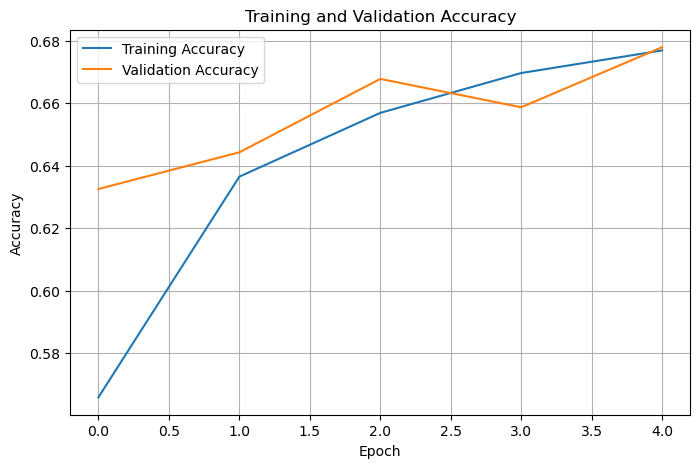

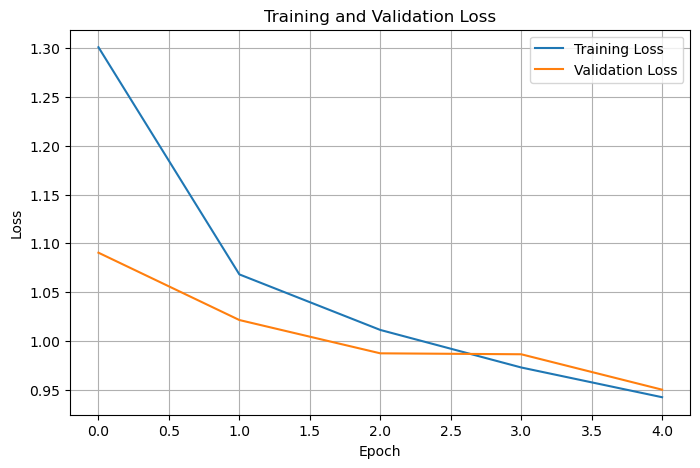

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(h1.history['accuracy'], label='Training Accuracy')
plt.plot(h1.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(h1.history['loss'], label='Training Loss')
plt.plot(h1.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# Para tener otra vez el modelo que mejor haya ido (si no lo hago se queda con los últimos weights y no con los mejores)
model.load_weights('model.keras')

print('\n--- FASE 2 ---')

base_model.trainable = True


for layer in base_model.layers:
    # Force ALL BatchNormalization layers to remain frozen
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.summary()

loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)
model.compile(optimizer=opt_phase2, loss=loss, metrics=['accuracy'])

epochs_phase2 = 20

h2 = model.fit(
    train_generator,
    steps_per_epoch=train_steps,
    validation_data=valid_generator,
    validation_steps=valid_steps,
    epochs=epochs_phase2,
    callbacks=callbacks,
    verbose=1
)


--- FASE 2 ---


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │         1,677 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,712,153 (17.98 MB)

 Trainable params: 4,131,177 (15.76 MB)

 Non-trainable params: 84,039 (328.28 KB)

 Optimizer params: 496,937 (1.90 MB)

Epoch 1/20


E0000 00:00:1763919896.972207   59592 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


528/528 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.6962 - loss: 1.3977
Epoch 1: val_accuracy improved from 0.67787 to 0.71253, saving model to model.keras
528/528 ━━━━━━━━━━━━━━━━━━━━ 113s 192ms/step - accuracy: 0.6962 - loss: 1.3976 - val_accuracy: 0.7125 - val_loss: 1.3022 - learning_rate: 1.0000e-05
Epoch 2/20
528/528 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.7215 - loss: 1.2735
Epoch 2: val_accuracy improved from 0.71253 to 0.71947, saving model to model.keras
528/528 ━━━━━━━━━━━━━━━━━━━━ 100s 190ms/step - accuracy: 0.7215 - loss: 1.2735 - val_accuracy: 0.7195 - val_loss: 1.2577 - learning_rate: 1.0000e-05
Epoch 3/20
528/528 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.7351 - loss: 1.2353
Epoch 3: val_accuracy improved from 0.71947 to 0.72373, saving model to model.keras
528/528 ━━━━━━━━━━━━━━━━━━━━ 99s 188ms/step - accuracy: 0.7351 - loss: 1.2353 - val_accuracy: 0.7237 - val_loss: 1.2388 - learning_rate: 1.0000e-05
Epoch 4/20
528/528 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/

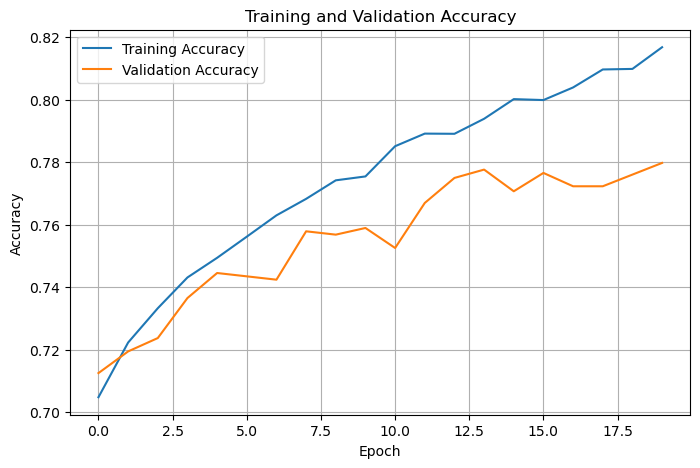

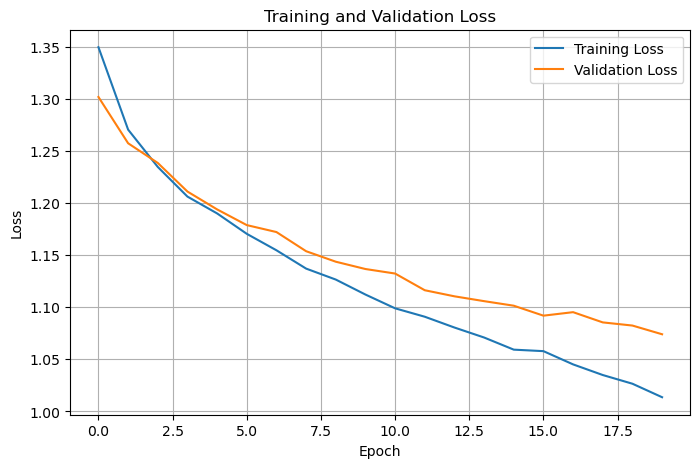

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(h2.history['accuracy'], label='Training Accuracy')
plt.plot(h2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(h2.history['loss'], label='Training Loss')
plt.plot(h2.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

#### Validation
Compute validation metrics.

In [ ]:
if not _FAST_EXEC:   
    import matplotlib.pyplot as plt
    import numpy as np
    %matplotlib inline

    def draw_confusion_matrix(cm, categories):
        # Draw confusion matrix
        fig = plt.figure(figsize=[6.4*pow(len(categories), 0.5), 4.8*pow(len(categories), 0.5)])
        ax = fig.add_subplot(111)
        cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], np.finfo(np.float64).eps)
        im = ax.imshow(cm, interpolation='nearest', cmap=plt.colormaps['Blues'])
        ax.figure.colorbar(im, ax=ax)
        ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]), xticklabels=list(categories.values()), yticklabels=list(categories.values()), ylabel='Annotation', xlabel='Prediction')
        # Rotate the tick labels and set their alignment
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
        # Loop over data dimensions and create text annotations
        thresh = cm.max() / 2.0
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, format(cm[i, j], '.2f'), ha="center", va="center", color="white" if cm[i, j] > thresh else "black", fontsize=int(20-pow(len(categories), 0.5)))
        fig.tight_layout()
        plt.show()

In [ ]:
if not _FAST_EXEC:
    import numpy as np
    
    model.load_weights('model.keras')
    y_true, y_pred = [], []
    for ann in anns_valid:
        # Load image
        image = load_geoimage(ann.filename)
        for obj_pred in ann.objects:
            # Generate prediction
            warped_image = np.expand_dims(image, 0)
            predictions = model.predict(warped_image, verbose=0)
            # Save prediction
            pred_category = list(categories.values())[np.argmax(predictions)]
            pred_score = np.max(predictions)
            y_true.append(obj_pred.category)
            y_pred.append(pred_category)

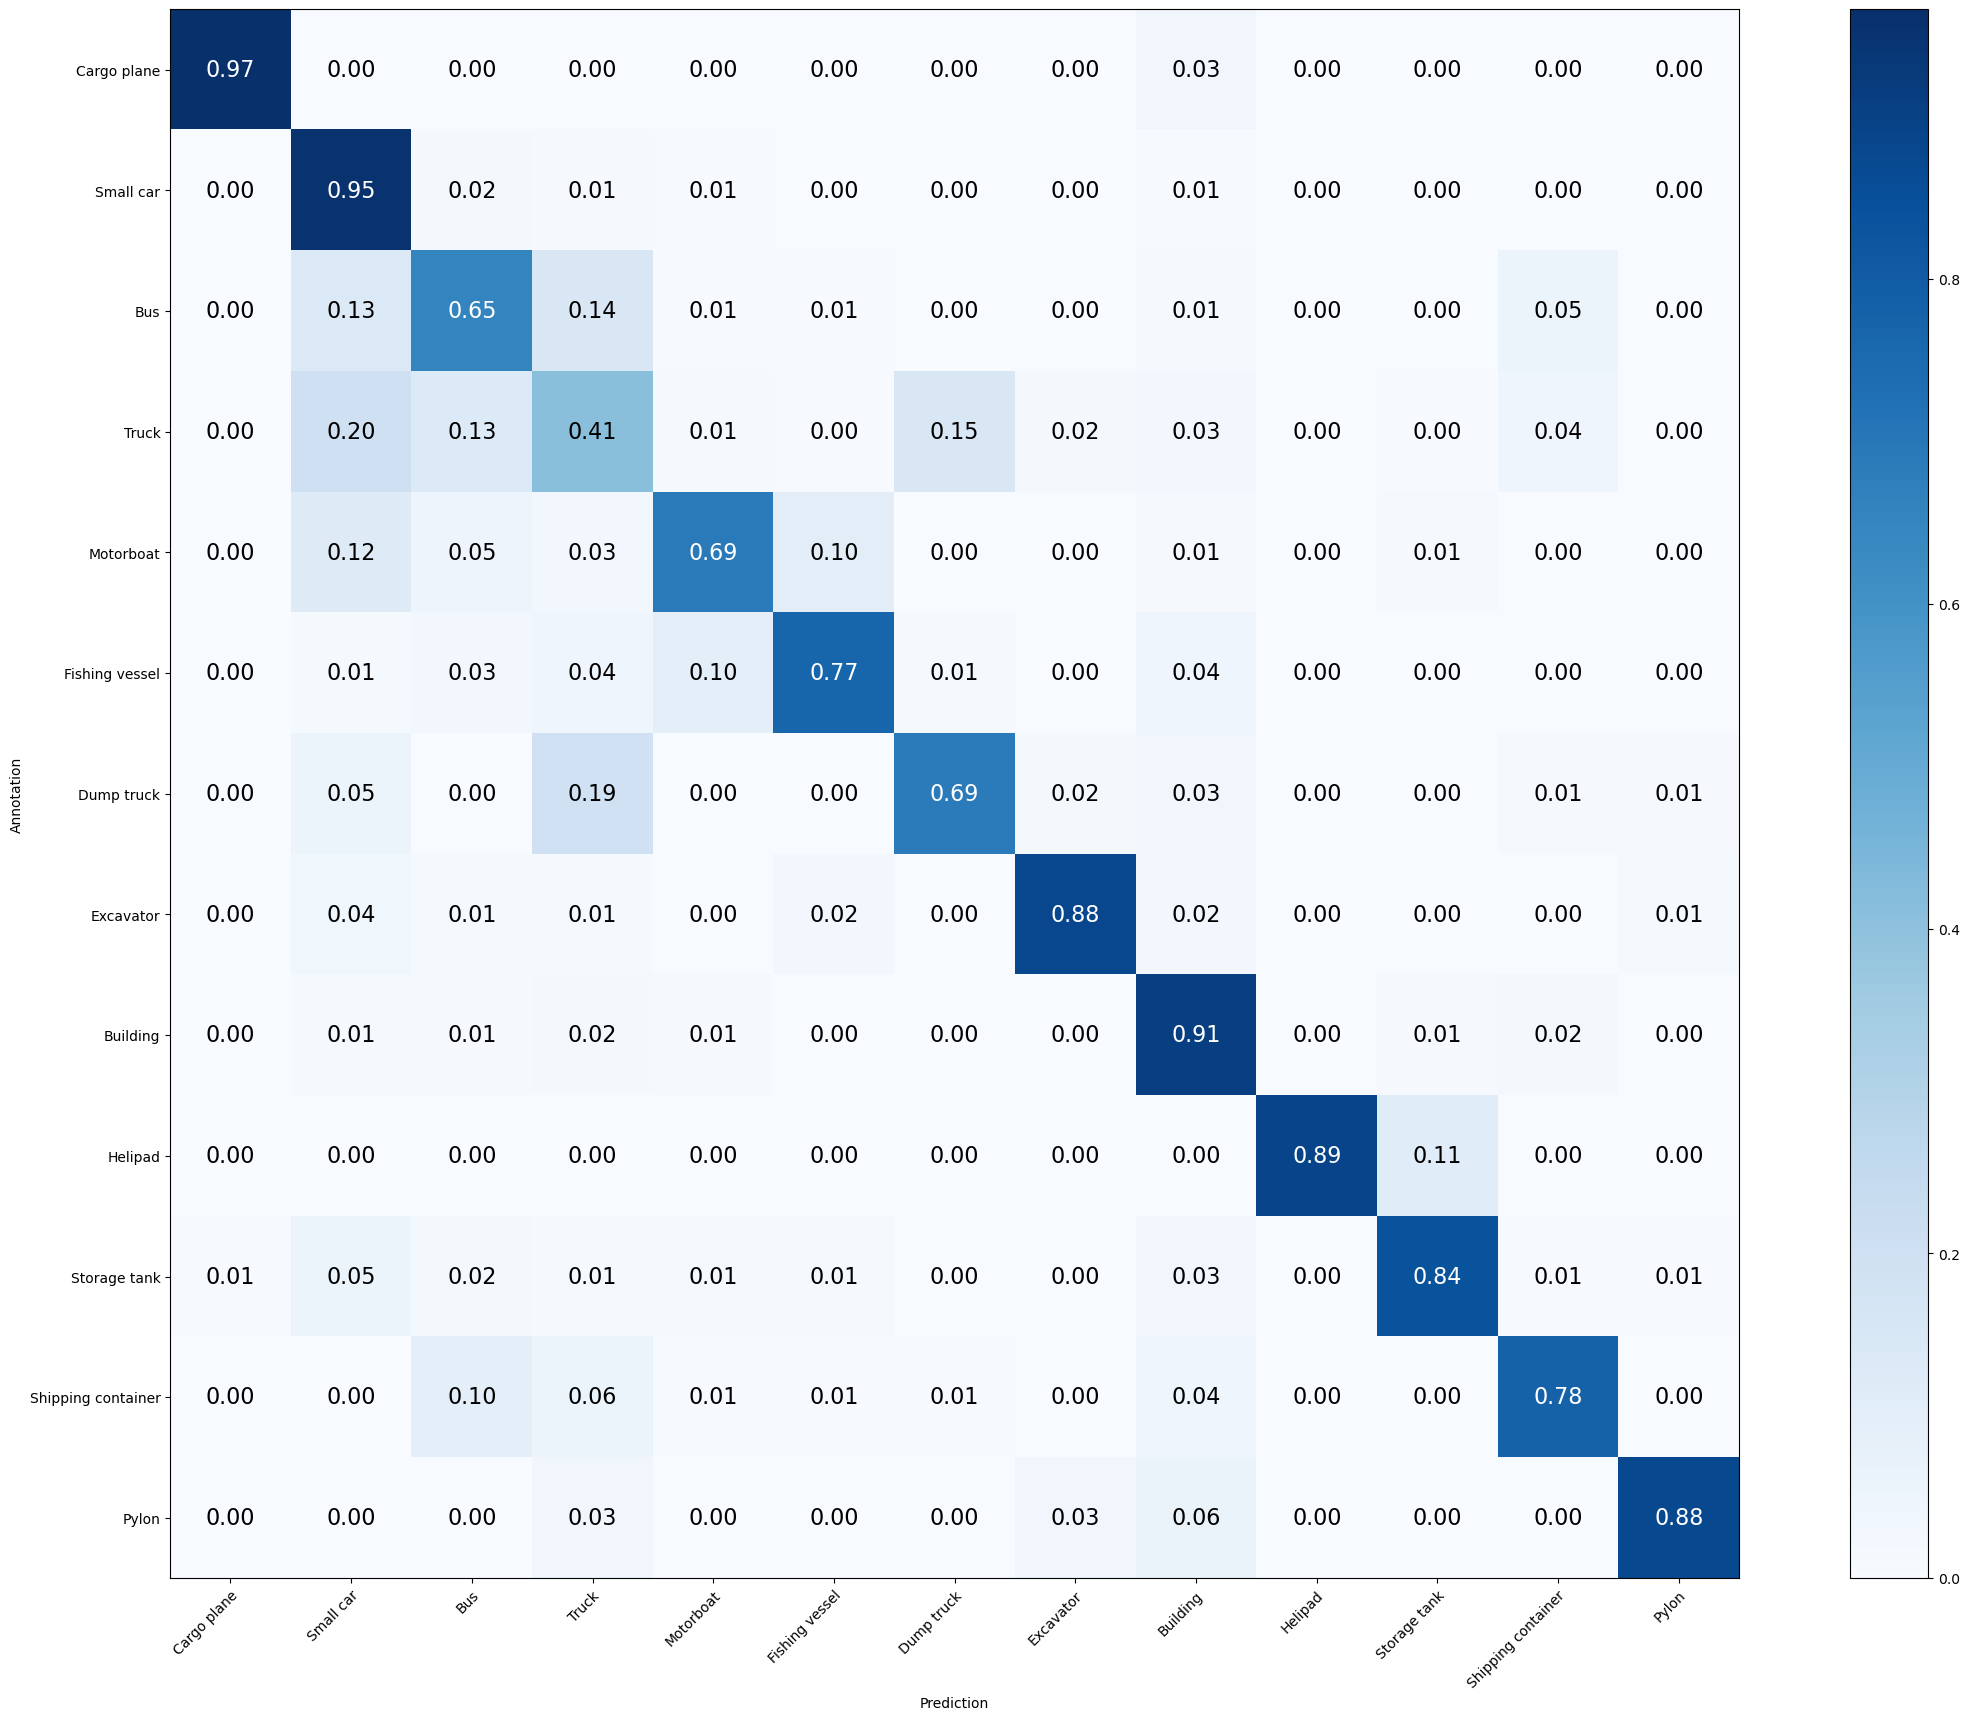

In [ ]:
if not _FAST_EXEC:
    from sklearn.metrics import confusion_matrix

    # Compute the confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=list(categories.values()))
    draw_confusion_matrix(cm, categories)

In [ ]:
if not _FAST_EXEC: 
    import numpy as np

    # Compute the accuracy
    correct_samples_class = np.diag(cm).astype(float)
    total_samples_class = np.sum(cm, axis=1).astype(float)
    total_predicts_class = np.sum(cm, axis=0).astype(float)
    print('Mean Accuracy: %.3f%%' % (np.sum(correct_samples_class) / np.sum(total_samples_class) * 100))
    acc = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
    print('Mean Recall: %.3f%%' % (acc.mean() * 100))
    acc = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
    print('Mean Precision: %.3f%%' % (acc.mean() * 100))
    for idx in range(len(categories)):
        # True/False Positives (TP/FP) refer to the number of predicted positives that were correct/incorrect.
        # True/False Negatives (TN/FN) refer to the number of predicted negatives that were correct/incorrect.
        tp = cm[idx, idx]
        fp = sum(cm[:, idx]) - tp
        fn = sum(cm[idx, :]) - tp
        tn = sum(np.delete(sum(cm) - cm[idx, :], idx))
        # True Positive Rate: proportion of real positive cases that were correctly predicted as positive.
        recall = tp / np.maximum(tp+fn, np.finfo(np.float64).eps)
        # Precision: proportion of predicted positive cases that were truly real positives.
        precision = tp / np.maximum(tp+fp, np.finfo(np.float64).eps)
        # True Negative Rate: proportion of real negative cases that were correctly predicted as negative.
        specificity = tn / np.maximum(tn+fp, np.finfo(np.float64).eps)
        # Dice coefficient refers to two times the intersection of two sets divided by the sum of their areas.
        # Dice = 2 |A∩B| / (|A|+|B|) = 2 TP / (2 TP + FP + FN)
        f1_score = 2 * ((precision * recall) / np.maximum(precision+recall, np.finfo(np.float64).eps))
        print('> %s: Recall: %.3f%% Precision: %.3f%% Specificity: %.3f%% Dice: %.3f%%' % (list(categories.values())[idx], recall*100, precision*100, specificity*100, f1_score*100))

Mean Accuracy: 78.027%
Mean Recall: 79.096%
Mean Precision: 81.144%
> Cargo plane: Recall: 96.610% Precision: 98.276% Specificity: 99.945% Dice: 97.436%
> Small car: Recall: 95.441% Precision: 74.408% Specificity: 93.014% Dice: 83.622%
> Bus: Recall: 64.943% Precision: 63.483% Specificity: 96.179% Dice: 64.205%
> Truck: Recall: 41.079% Precision: 56.250% Specificity: 95.288% Dice: 47.482%
> Motorboat: Recall: 68.807% Precision: 78.947% Specificity: 98.867% Dice: 73.529%
> Fishing vessel: Recall: 76.712% Precision: 74.667% Specificity: 98.946% Dice: 75.676%
> Dump truck: Recall: 68.644% Precision: 68.067% Specificity: 97.837% Dice: 68.354%
> Excavator: Recall: 87.654% Precision: 89.873% Specificity: 99.554% Dice: 88.750%
> Building: Recall: 90.634% Precision: 90.137% Specificity: 97.619% Dice: 90.385%
> Helipad: Recall: 88.889% Precision: 100.000% Specificity: 100.000% Dice: 94.118%
> Storage tank: Recall: 83.553% Precision: 95.489% Specificity: 99.652% Dice: 89.123%
> Shipping containe

#### Testing
Try to improve the results provided in the competition.

In [29]:
import os
import numpy as np

anns = []
for (dirpath, dirnames, filenames) in os.walk(_DATASET_PATH+'/xview_test'):
    for filename in filenames:
        image = GenericImage(os.path.relpath(dirpath, _DATASET_PATH)  + '/' + filename)
        image.tile = np.array([0, 0, 224, 224])
        obj = GenericObject()
        obj.bb = (0, 0, 224, 224)
        obj.category = dirpath[dirpath.rfind('/')+1:]
        image.add_object(obj)
        anns.append(image)
print('Number of testing images: ' + str(len(anns)))

Number of testing images: 2365


In [30]:
import numpy as np

model.load_weights('model.keras')
predictions_data = {"images": {}, "annotations": {}}
for idx, ann in enumerate(anns):
    image_data = {"image_id": ann.filename.split('/')[-1], "filename": ann.filename, "width": int(ann.tile[2]), "height": int(ann.tile[3])}
    predictions_data["images"][idx] = image_data
    # Load image
    image = load_geoimage(ann.filename)
    for obj_pred in ann.objects:
        # Generate prediction
        warped_image = np.expand_dims(image, 0)
        predictions = model.predict(warped_image, verbose=0)
        # Save prediction
        pred_category = list(categories.values())[np.argmax(predictions)]
        pred_score = np.max(predictions)
        annotation_data = {"image_id": ann.filename.split('/')[-1], "category_id": pred_category, "bbox": [int(x) for x in obj_pred.bb]}
        predictions_data["annotations"][idx] = annotation_data

In [31]:
with open("prediction.json", "w") as outfile:
    json.dump(predictions_data, outfile)